In [1]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      !pip install py3Dmol
      !pip install rdkit
      pbar.update(50)
      from rdkit import Chem
      from rdkit.Chem import Draw
      from rdkit.Chem.Draw import IPythonConsole
      from rdkit.Chem import AllChem # import the AllChem submodule from the Chem module
      from rdkit.Chem import rdDistGeom
      from rdkit.Chem import rdDepictor
      from IPython.display import Image
      import py3Dmol


      pbar.update(50)

  0%|          | 0/100 [00:00<?, ?it/s]

In [2]:
talS = Chem.MolFromSmiles('C1CC(=O)NC(=O)[C@H]1N2C(=O)C3=CC=CC=C3C2=O')
talR = Chem.MolFromSmiles('C1CC(=O)NC(=O)[C@@H]1N2C(=O)C3=CC=CC=C3C2=O')
talS, talR

(<rdkit.Chem.rdchem.Mol at 0x7fc8b4410900>,
 <rdkit.Chem.rdchem.Mol at 0x7fc8b47ab1b0>)

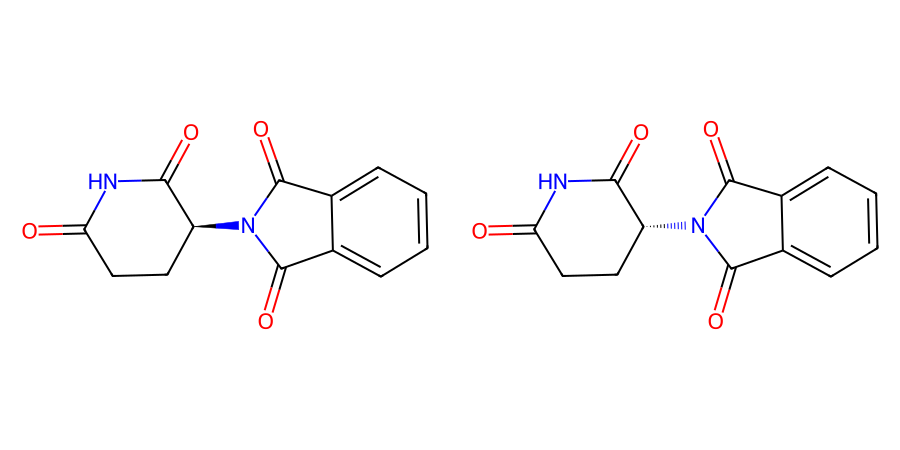

In [4]:
Draw.MolsToGridImage((talS, talR), subImgSize=(450,450), molsPerRow=2)

In [5]:
def smi2conf(smiles):
    '''Convert SMILES to rdkit.Mol with 3D coordinates'''
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        mol = Chem.AddHs(mol)   #Agregar Hidrógenos
        AllChem.EmbedMolecule(mol) #Generar conformaciones
        AllChem.MMFFOptimizeMolecule(mol, maxIters=200) #Campo de fuerza
        return mol
    else:
        return None

In [6]:
talS = smi2conf(Chem.MolToSmiles(talS))
talR = smi2conf(Chem.MolToSmiles(talS))

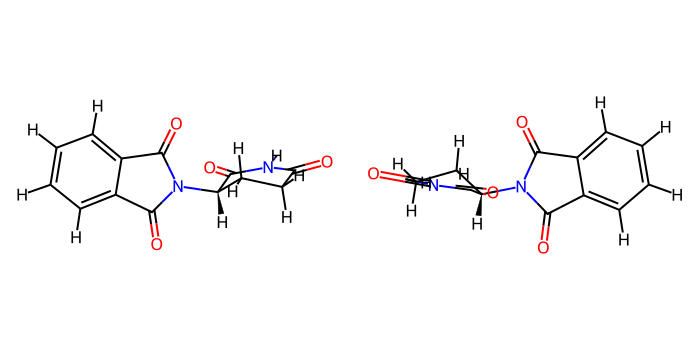

In [7]:
Draw.MolsToGridImage((talS, talR), subImgSize=(350,350), molsPerRow=2)

#pymol

In [8]:
ps = rdDistGeom.ETKDGv3()
ps.clearConfs= True
cidS = rdDistGeom.EmbedMolecule(talS,ps)
cidR = rdDistGeom.EmbedMolecule(talR,ps)

Imprimimos el primer conformero

In [9]:
v = py3Dmol.view(width=400,height=400)
v.removeAllModels()
IPythonConsole.addMolToView(talS,v,confId=0)
#v.setStyle({'model': 0, 'cartoon':{'colorscheme':'pinkCarbon'}}) # Target the second model
v.setStyle({'stick':{'colorscheme':'greenCarbon'}})
v.zoomTo()
v.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [10]:
v = py3Dmol.view(width=400,height=400)
v.removeAllModels()
IPythonConsole.addMolToView(talR,v,confId=0)
v.setStyle({'model': 0, 'stick':{'colorscheme':'pinkCarbon'}}) # Target the second model
#v.setStyle({'line':{'colorscheme':'greenCarbon'}})
v.zoomTo()
v.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [13]:
# import py3Dmol
# from rdkit import Chem
# from rdkit.Chem import AllChem

# # 1. Definir SMILES de los enantiómeros
smiles_S = "C1CC(=O)NC(=O)[C@H]1N2C(=O)C3=CC=CC=C3C2=O"  # (S)-Talidomida
smiles_R = "C1CC(=O)NC(=O)[C@@H]1N2C(=O)C3=CC=CC=C3C2=O" # (R)-Talidomida

# 2. Función para generar conformador 3D optimizado y devolver el bloque SDF/MOL
def get_3d_mol_block(smiles):
    mol = Chem.MolFromSmiles(smiles)
    mol = Chem.AddHs(mol)
    AllChem.EmbedMolecule(mol, randomSeed=42)
    AllChem.MMFFOptimizeMolecule(mol)
    return Chem.MolToMolBlock(mol)

block_S = get_3d_mol_block(smiles_S)
block_R = get_3d_mol_block(smiles_R)

# 3. Visualización con py3Dmol (Visor dividido 1 fila, 2 columnas)
view = py3Dmol.view(width=800, height=400, linked=False, viewergrid=(1, 2))

# Subpantalla izquierda (0,0): talS en color Cian / Azul Claro
view.addModel(block_S, 'mol', viewer=(0, 0))
view.setStyle({'model': -1}, {'stick': {#'color': 'cyan'
                                        }}, viewer=(0, 0))
view.addSurface(py3Dmol.VDW, {'opacity': 0.3, 'color': 'cyan'}, viewer=(0, 0))
view.zoomTo(viewer=(0, 0))

# Subpantalla derecha (0,1): talR en color Anaranjado / Magenta
view.addModel(block_R, 'mol', viewer=(0, 1))
view.setStyle({'model': -1}, {'stick': {#'color': 'orange'
                                        }}, viewer=(0, 1))
view.addSurface(py3Dmol.VDW, {'opacity': 0.3, 'color': 'orange'}, viewer=(0, 1))
view.zoomTo(viewer=(0, 1))

view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [17]:
# import py3Dmol
# from rdkit import Chem
from rdkit.Chem import AllChem, rdMolAlign

# # 1. Definir SMILES
# smiles_S = "C1CC(=O)NC(=O)[C@H]1N2C(=O)C3=CC=CC=C3C2=O"  # (S)-Talidomida
# smiles_R = "C1CC(=O)NC(=O)[C@@H]1N2C(=O)C3=CC=CC=C3C2=O" # (R)-Talidomida

# 2. Generar moléculas 3D optimizadas
def gen_3d_mol(smiles):
    mol = Chem.MolFromSmiles(smiles)
    mol = Chem.AddHs(mol)
    AllChem.EmbedMolecule(mol, randomSeed=42)
    AllChem.MMFFOptimizeMolecule(mol)
    return mol

mol_S = gen_3d_mol(smiles_S)
mol_R = gen_3d_mol(smiles_R)

# 3. Superponer/Alinear talR sobre talS en el espacio 3D
rdMolAlign.AlignMol(mol_R, mol_S)

# Convertir a bloques de texto MOL
block_S = Chem.MolToMolBlock(mol_S)
block_R = Chem.MolToMolBlock(mol_R)

# 4. Crear un único visor py3Dmol
view = py3Dmol.view(width=700, height=500)

# Agregar talS (Modelo 0) -> Carbonos en Azul / Cian
view.addModel(block_S, 'mol')
view.setStyle({'model': 0}, {'stick': {'colorscheme': 'cyanCarbon'}})

# Agregar talR (Modelo 1) -> Carbonos en Rosa / Anaranjado
view.addModel(block_R, 'mol')
view.setStyle({'model': 1}, {'stick': {'colorscheme': 'orangeCarbon'}})

view.zoomTo()
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.